## Pregunta 5
##### Cuales son los pokemons legendarios con mas capture rate ("capture_rate")? 

In [2]:
# Importamos todas las librerias necesarias para mostrar y filtrar los datos correctamente
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aplicamos el estilo de seaborn a los graficos y los mostramos dentro del notebook
sns.set_theme(style="whitegrid")
%matplotlib inline

In [3]:
df = pd.read_csv("pokemon.csv")
print(f"Dataset carregat: {df.shape[0]} files i {df.shape[1]} columnes.")

Dataset carregat: 1025 files i 15 columnes.


In [4]:
# Guardamos en una variable solo los pokemon legendarios
df_legendarios = df[df['is_legendary'] == True]

# Mostramos cuantos legendarios hay en el dataset
print(f"Pokemon legendarios: {df_legendarios.shape[0]} de {df.shape[0]}")

Pokemon legendarios: 71 de 1025


In [5]:
# Obtenemos la fila del legendario con mayor capture_rate
idx_max = df_legendarios['capture_rate'].idxmax()
mayor_capture = df_legendarios.loc[[idx_max], ['name', 'capture_rate']]

# Mostramos el resultado
mayor_capture

,name,capture_rate
143,Necrozma,255


In [6]:
# Mostramos los 10 legendarios con mayor capture_rate
top_10_capture = (
    df_legendarios[['name', 'capture_rate']]
    .sort_values(by='capture_rate', ascending=False)  # Ordena de mayor a menor capture_rate
    .head(10)                                         # Se queda con las 10 primeras filas
    .reset_index(drop=True)                           # Renumera el indice desde 0
)

# Mostramos el resultado
top_10_capture

,name,capture_rate
0,Necrozma,255
1,Eternatus,255
2,Terapagos,255
3,Rayquaza,45
4,Xerneas,45
5,Yveltal,45
6,Cosmog,45
7,Cosmoem,45
8,Solgaleo,45
9,Lunala,45


In [7]:
# Contamos cuantos legendarios hay en cada valor de capture_rate
distribucion_capture = (
    df_legendarios.groupby('capture_rate')
    .agg(cantidad=('name', 'count'),                          # Cuantos legendarios tienen ese valor
         ejemplos=('name', lambda x: ', '.join(x.head(3))))   # Hasta 3 nombres de ejemplo
    .reset_index()                                            # Convierte capture_rate de indice a columna
    .sort_values(by='capture_rate', ascending=False)          # Ordena de mayor a menor
)

# Mostramos el resultado
distribucion_capture

,capture_rate,cantidad,ejemplos
5,255,3,"Necrozma, Eternatus, Terapagos"
4,45,7,"Rayquaza, Xerneas, Yveltal"
3,10,2,"Zacian, Zamazenta"
2,6,4,"Wo-Chien, Chien-Pao, Ting-Lu"
1,5,1,Ogerpon
0,3,54,"Articuno, Zapdos, Moltres"


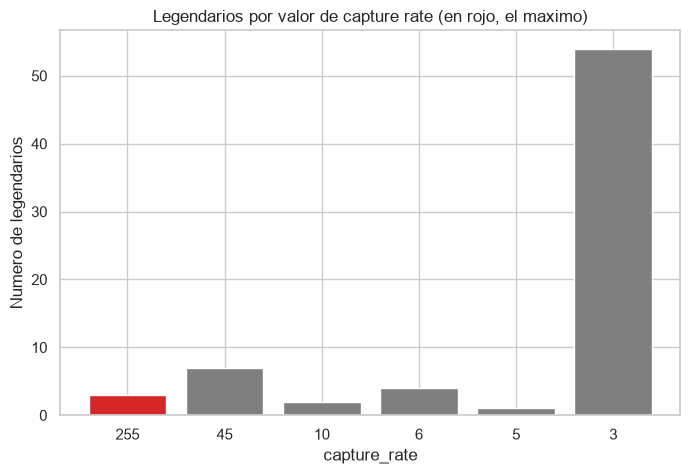

In [10]:
# Marcamos en otro color el valor maximo de capture_rate
maximo = df_legendarios['capture_rate'].max()
colores = ['tab:red' if v == maximo else 'tab:gray' for v in distribucion_capture['capture_rate']]

# Dibujamos cuantos legendarios hay en cada valor de capture_rate
plt.figure(figsize=(8, 5))
plt.bar(distribucion_capture['capture_rate'].astype(str), distribucion_capture['cantidad'], color=colores)
plt.xlabel('capture_rate')
plt.ylabel('Numero de legendarios')
plt.title('Legendarios por valor de capture rate (en rojo, el maximo)')
plt.show()

### Este código responde a una pregunta sencilla: ¿los Pokémon legendarios más fuertes son también los más difíciles de capturar?

In [13]:
# Correlacion entre capture_rate y base_stat_total en los legendarios
# (la correlacion es un numero que indica si dos cosas suben o bajan juntas)

# df_legendarios es la tabla que solo tiene los pokemon legendarios
# ['capture_rate'] elige la columna de dificultad de captura (mas alto = mas facil de capturar)
# .corr(...) compara esa columna con otra y calcula la correlacion
# ['base_stat_total'] es la otra columna: la fuerza total del pokemon
# El resultado se guarda en una variable llamada "correlacion"
correlacion = df_legendarios['capture_rate'].corr(df_legendarios['base_stat_total'])
print(f"Correlacion capture_rate vs base_stat_total: {correlacion:.2f}")

Correlacion capture_rate vs base_stat_total: -0.06


### La correlación entre la fuerza (base_stat_total) y el capture rate de los Pokémon legendarios es de -0.06, prácticamente nula. Esto indica que, en este dataset, los legendarios más fuertes no son necesariamente los más difíciles de capturar.